# Активация и удержание пользователей мобильного приложения

В этом разборе смотрю, как новые пользователи знакомятся с учебным приложением: открывают его, начинают обучение, доходят до первого урока и возвращаются позже.

Основные вопросы — где теряются пользователи в начале пути, какая доля активируется в первые сутки и как меняется возвращаемость на D1 и D7. Также сравниваю активацию по источнику привлечения и платформе.

**Данные:** синтетические, созданы для практики. Это не статистика реального приложения.

**Единицы измерения:** воронка и retention считаются по пользователям. Активация — завершение первого урока в течение 24 часов после регистрации. D1/D7 — наличие `session_started` на календарный день +1/+7 от даты регистрации.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
users = pd.read_csv(ROOT / "data/users.csv", parse_dates=["signup_date"])
events = pd.read_csv(ROOT / "data/events.csv", parse_dates=["event_time"])
print(f"Пользователей: {users.user_id.nunique():,}")
print(f"Событий: {len(events):,}")
users.head()

Пользователей: 2,800
Событий: 14,804


,user_id,signup_date,platform,acquisition_channel
0,U00001,2025-01-21,Android,Organic
1,U00002,2025-02-05,Android,Referral
2,U00003,2025-02-14,Android,Paid Ads
3,U00004,2025-02-23,Android,Organic
4,U00005,2025-02-24,Android,Organic


## Подготовка данных

Сначала проверяю размеры таблиц, типы и пропуски. Затем убеждаюсь, что идентификаторы пользователей и событий не дублируются, а каждое событие относится к пользователю из таблицы регистраций.


In [2]:
print("Пропуски в users:")
display(users.isna().sum())
print("Дубликаты user_id:", users.user_id.duplicated().sum())
print("Дубликаты event_id:", events.event_id.duplicated().sum())
print("События без пользователя:", (~events.user_id.isin(users.user_id)).sum())
print(); print("Период регистрации:", users.signup_date.min().date(), "—", users.signup_date.max().date())

Пропуски в users:


user_id                0
signup_date            0
platform               0
acquisition_channel    0
dtype: int64

Дубликаты user_id: 0
Дубликаты event_id: 0
События без пользователя: 0

Период регистрации: 2025-01-01 — 2025-02-24


## Первые шаги пользователя

Собираю воронку по уникальным пользователям: открытие приложения → начало обучения → завершение обучения → начало первого урока → завершение первого урока.

Для каждого шага считаю количество пользователей и конверсию относительно регистрации и предыдущего шага. В этом наборе данных последовательность событий задана генератором, поэтому для учебной оценки использую наличие каждого события.


In [3]:
steps = [
    ("app_opened", "Открыл приложение"),
    ("tutorial_started", "Начал обучение"),
    ("tutorial_completed", "Завершил обучение"),
    ("first_lesson_started", "Начал первый урок"),
    ("first_lesson_completed", "Завершил первый урок"),
]
funnel = pd.DataFrame([
    {"event_name": event, "step": label, "users": events.loc[events.event_name.eq(event), "user_id"].nunique()}
    for event, label in steps
])
funnel["conversion_from_signup"] = funnel.users / users.user_id.nunique()
funnel["conversion_from_previous"] = funnel.users / funnel.users.shift(1)
funnel.loc[0, "conversion_from_previous"] = 1.0
display(funnel)

,event_name,step,users,conversion_from_signup,conversion_from_previous
0,app_opened,Открыл приложение,2800,1.000000,1.000000
1,tutorial_started,Начал обучение,2308,0.824286,0.824286
2,tutorial_completed,Завершил обучение,1860,0.664286,0.805893
3,first_lesson_started,Начал первый урок,1605,0.573214,0.862903
4,first_lesson_completed,Завершил первый урок,1298,0.463571,0.808723


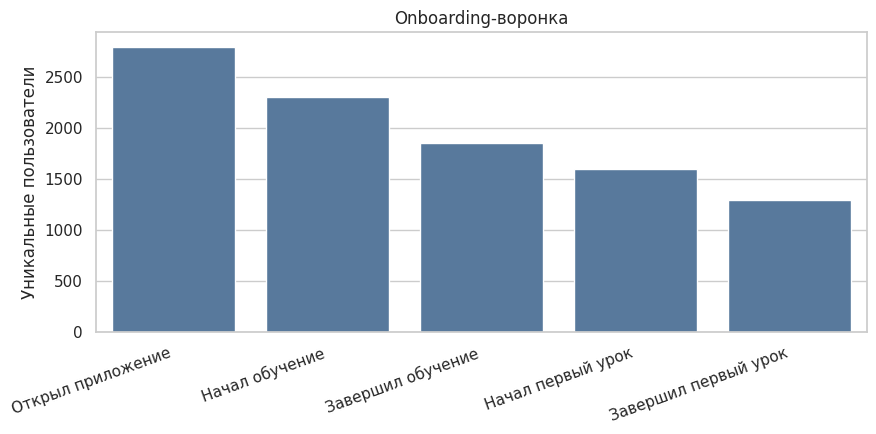

In [4]:
plt.figure(figsize=(9, 4.5))
sns.barplot(data=funnel, x="step", y="users", color="#4C78A8")
plt.xticks(rotation=20, ha="right")
plt.ylabel("Уникальные пользователи")
plt.xlabel("")
plt.title("Onboarding-воронка")
plt.tight_layout()
plt.show()

## Активация в первые сутки

Пользователь считается активированным, если событие `first_lesson_completed` произошло не позднее чем через 24 часа после регистрации. Завершение урока через несколько дней в эту метрику не попадает.


In [5]:
activation_events = events.loc[events.event_name.eq("first_lesson_completed")].merge(
    users[["user_id", "signup_date"]], on="user_id", how="left"
)
activation_events["hours_since_signup"] = (activation_events.event_time - activation_events.signup_date).dt.total_seconds() / 3600
activated_users = activation_events.loc[activation_events.hours_since_signup.between(0, 24), "user_id"].nunique()
activation_rate = activated_users / users.user_id.nunique()
print(f"Активировались за 24 часа: {activated_users:,} пользователей")
print(f"Activation rate: {activation_rate:.1%}")

Активировались за 24 часа: 1,298 пользователей
Activation rate: 46.4%


## Возвращаемость на D1 и D7

Считаю пользователя вернувшимся, если после регистрации у него есть событие `session_started` на следующий календарный день (D1) или на седьмой календарный день (D7).

Это календарное определение: оно отличается от окна в 24 или 168 часов.


,day,returned_users,retention
0,D1,954,0.340714
1,D7,519,0.185357


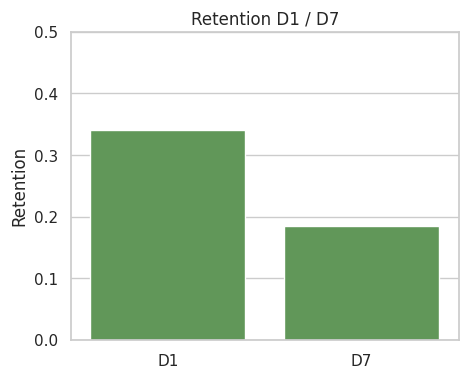

In [6]:
sessions = events.loc[events.event_name.eq("session_started")].merge(
    users[["user_id", "signup_date"]], on="user_id", how="left"
)
sessions["days_after_signup"] = (sessions.event_time.dt.normalize() - sessions.signup_date.dt.normalize()).dt.days
retention_rows = []
for day in [1, 7]:
    returned = sessions.loc[sessions.days_after_signup.eq(day), "user_id"].nunique()
    retention_rows.append({"day": f"D{day}", "returned_users": returned, "retention": returned / users.user_id.nunique()})
retention = pd.DataFrame(retention_rows)
display(retention)
plt.figure(figsize=(5, 4))
sns.barplot(data=retention, x="day", y="retention", color="#59A14F")
plt.ylim(0, 0.5)
plt.ylabel("Retention")
plt.xlabel("")
plt.title("Retention D1 / D7")
plt.show()

## Активация по каналам и платформам

Сравниваю долю активированных пользователей между каналами привлечения и платформами. Это описательная разбивка: она помогает найти различия для дальнейшего изучения, но не показывает, чем именно эти различия вызваны.


In [7]:
user_metrics = users.copy()
user_metrics["activated_24h"] = user_metrics.user_id.isin(activation_events.loc[activation_events.hours_since_signup.between(0, 24), "user_id"])
channel_activation = user_metrics.groupby("acquisition_channel", as_index=False).activated_24h.mean().sort_values("activated_24h", ascending=False)
platform_activation = user_metrics.groupby("platform", as_index=False).activated_24h.mean().sort_values("activated_24h", ascending=False)
print("По каналу привлечения:")
display(channel_activation)
print("По платформе:")
display(platform_activation)

По каналу привлечения:


,acquisition_channel,activated_24h
2,Referral,0.599537
0,Organic,0.501479
1,Paid Ads,0.355315


По платформе:


,platform,activated_24h
1,iOS,0.535382
0,Android,0.418888


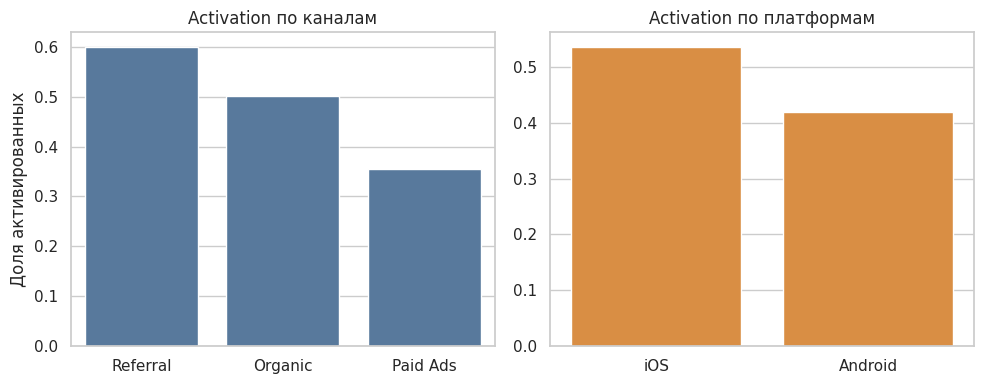

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=channel_activation, x="acquisition_channel", y="activated_24h", ax=axes[0], color="#4C78A8")
axes[0].set_title("Activation по каналам")
axes[0].set_xlabel(""); axes[0].set_ylabel("Доля активированных")
sns.barplot(data=platform_activation, x="platform", y="activated_24h", ax=axes[1], color="#F28E2B")
axes[1].set_title("Activation по платформам")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

## Что получилось

- В воронке самое большое абсолютное снижение — между открытием приложения и началом обучения: до следующего шага не дошли **492 пользователя**.
- За первые 24 часа первый урок завершили **46,4%** зарегистрированных пользователей.
- Retention составил **34,1% на D1** и **18,5% на D7**.
- По каналам самая высокая активация у Referral (**60,0%**), самая низкая — у Paid Ads (**35,5%**). На iOS активация составила **53,5%**, на Android — **41,9%**.

Первое направление для продуктовой проверки — путь от первого открытия до начала обучения. Разницу по каналам и платформам стоит дополнительно разобрать по составу аудитории и качеству трафика. Эти наблюдения сами по себе не доказывают причинность; эффект изменений нужно проверять отдельно.


In [9]:
biggest_drop = funnel.assign(drop=funnel.users.shift(1) - funnel.users).iloc[1:].sort_values("drop", ascending=False).iloc[0]
print(f"Самая большая абсолютная потеря между шагами: перед шагом «{biggest_drop['step']}» — {int(biggest_drop['drop'])} пользователей.")
print(f"Activation rate за 24 часа: {activation_rate:.1%}")
print("Retention D1 / D7:", ", ".join(f"{r.day}: {r.retention:.1%}" for r in retention.itertuples()))

Самая большая абсолютная потеря между шагами: перед шагом «Начал обучение» — 492 пользователей.
Activation rate за 24 часа: 46.4%
Retention D1 / D7: D1: 34.1%, D7: 18.5%


## Ограничения

- Все данные синтетические, поэтому значения нельзя использовать как отраслевые ориентиры.
- Воронка построена по наличию событий. Порядок и интервалы между ними в реальном продукте нужно проверять отдельно.
- D1 и D7 считаются по календарным дням, а не по скользящим окнам в 24 и 168 часов.
- Разбивки по каналам и платформам показывают корреляции, а не причины различий.
